# 🧠 01 · The Thresholded Perceptron

> **Module 01 – Perceptron and Gradient Descent** · Notebook 1 of 3
> Course notes: *Perceptron* (page 2 of the handwritten notes) · Book reference: Tom Mitchell, *Machine Learning*, Ch. 4 (ANN)

The perceptron is the **simplest possible artificial neuron**. It is the atom from which every network in this repository (FFNN → RNN → Transformer → GPT) is built, so it is worth understanding it completely.

### 🎯 What you will learn

| # | Idea | Why it matters |
|---|---|---|
| 1 | Why we copy the brain at all | It explains the "many simple units in parallel" design |
| 2 | What one neuron computes: $net=\sum_i w_ix_i$, then a hard step | This weighted sum is inside *every* later model |
| 3 | The picture: a perceptron draws **one straight line** (hyperplane) | Tells us exactly what it can and cannot learn |
| 4 | The **perceptron learning rule** $\Delta w_i=\eta\ (t-o)\ x_i$ | Our first learning algorithm |
| 5 | It learns AND / OR, but **never XOR** | The failure that motivates everything that follows |

### 🗺️ Where this sits

```
[ Thresholded perceptron ] ──► Unthresholded (Delta rule) ──► Sigmoid unit ──► FFNN + Backprop ──► ...
        you are here
```

## 0 · Setup

Only **NumPy** (numbers) and **Matplotlib** (pictures) are needed. The cell below also sets one clean colour style that every figure in this notebook uses.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- one consistent, clean plotting style for the whole notebook ----------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", muted="#52514e", grid="#e6e5e1")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
                       ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
REGION_CMAP = ListedColormap(["#d6e6f8", "#fcdccd"])   # light fill: class -1 (blue side) / +1 (orange side)
POINT_CMAP  = ListedColormap([C["blue"], C["orange"]])  # strong colour for the data points
np.set_printoptions(precision=3, suppress=True)
print("NumPy", np.__version__, "| ready")

NumPy 2.5.3 | ready


---
## 1 · Why copy the brain? 🧬

The course notes open with four numbers about the human brain:

| Fact | Value | What it tells us |
|---|---|---|
| Number of neurons | $\approx 10^{11}$ | a **huge** number of very simple units |
| Connections per neuron | $\approx 10^{4}$ | each unit listens to many others |
| Neuron switching time | $\approx 10^{-3}$ s | each unit is **slow** (a CPU switches in $10^{-10}$ s) |
| Time to recognise a face | $\approx 10^{-1}$ s | ... yet the whole decision is fast |

**The puzzle.** $10^{-1}\ \text{s} \ /\  10^{-3}\ \text{s} = 100$. So the brain can only do about **100 steps one after another** to recognise a face. No long sequential program fits in 100 steps.

**The conclusion (from the notes):**
* ➜ **Parallel processing** – lots of simple work happens at the same time.
* ➜ **Distributed representation** – knowledge is spread across many connection strengths; you cannot point to one place where "the information" is.
* ➜ **No explicit coding of the algorithm** – the connection strengths are *learned* from examples.

An artificial neural network copies exactly this recipe: **many simple units + learnable connection weights**. The perceptron is that simple unit.

---
## 2 · The variables (read this before any formula) 📖

Every symbol used in this notebook, with its meaning and a concrete example:

| Symbol | Name | Meaning in plain words | Example |
|---|---|---|---|
| $n$ | number of inputs | how many features describe one example | AND gate: $n=2$ |
| $x_i$ | input $i$ ($i=1..n$) | the value of feature $i$ | $x_1=1$ ("first switch on") |
| $x_0$ | bias input | a constant input that is **always 1** | $x_0=1$ |
| $\vec x=(x_0,x_1,\dots,x_n)$ | input vector | all inputs of one example, bias included | $(1,\ 0,\ 1)$ |
| $w_i$ | weight $i$ | how strongly input $i$ pushes the decision (+ = towards YES, − = towards NO) | $w_1=0.4$ |
| $w_0$ | bias weight | the neuron's *default opinion* when all real inputs are 0 | $w_0=-0.4$ |
| $net$ | net input | the weighted sum $\sum_{i=0}^{n}w_ix_i$ | $0.2$ |
| $o$ (or $y$) | output | the neuron's answer, **+1 (YES)** or **−1 (NO)** | $+1$ |
| $t$ | target | the correct answer from the dataset | $-1$ |
| $\eta$ (eta) | learning rate | size of each correction step, a small positive number | $0.1$ |
| $D$ | dataset | the set of training examples $(\vec x, t)$ | the 4 rows of AND |
| epoch | – | one full pass over all of $D$ | – |

---
## 3 · What one neuron computes ⚙️

Two steps: **(1) add up the evidence, (2) make a hard yes/no decision.**

$$\boxed{\ net=\sum_{i=0}^{n} w_i\ x_i = w_0 + w_1x_1 + \dots + w_nx_n\ }\qquad\qquad \boxed{\ o=\begin{cases}+1 & \text{if } net>0\cr  -1 & \text{otherwise}\end{cases}}$$

The sum is just a **dot product** $\vec w\cdot\vec x$ – multiply matching entries and add.

### 🏏 Everyday example: *"Should I go to the cricket match?"*
| input | meaning | weight | why this sign? |
|---|---|---|---|
| $x_1$ | is it a weekend? (0/1) | $w_1=+2$ | weekends make me want to go |
| $x_2$ | is my friend coming? (0/1) | $w_2=+1$ | company helps a bit |
| $x_3$ | is it raining? (0/1) | $w_3=-3$ | rain strongly pushes me to stay home |
| $x_0=1$ | bias | $w_0=-1.5$ | by default I'm lazy (lean towards NO) |

Let us compute it in code – exactly the two steps above.

In [2]:
w = np.array([-1.5, 2.0, 1.0, -3.0])          # [w0 (bias), w1 weekend, w2 friend, w3 rain]

situations = {
    "Saturday, friend, no rain": [1, 1, 1, 0],  # first entry is always x0 = 1
    "Saturday, friend, raining": [1, 1, 1, 1],
    "Weekday, friend, no rain":  [1, 0, 1, 0],
    "Saturday, alone, no rain":  [1, 1, 0, 0],
}

print(f"{'situation':<28}{'net = w·x':>12}{'output':>9}")
for name, x in situations.items():
    net = np.dot(w, x)                          # step 1: weighted sum (dot product)
    o = 1 if net > 0 else -1                    # step 2: hard threshold
    print(f"{name:<28}{net:>12.1f}{o:>+9d}   {'→ go 🎉' if o == 1 else '→ stay home'}")

situation                      net = w·x   output
Saturday, friend, no rain            1.5       +1   → go 🎉
Saturday, friend, raining           -1.5       -1   → stay home
Weekday, friend, no rain            -0.5       -1   → stay home
Saturday, alone, no rain             0.5       +1   → go 🎉


### Why do we need the bias $x_0 = 1$?

Without $w_0$, an input of all zeros always gives $net = 0$, so the neuron would be forced to answer "−1" for the empty input no matter what. Mathematically, the decision line $w_1x_1+w_2x_2=0$ would be **pinned to the origin**. Adding a constant input $x_0=1$ with its own learnable weight $w_0$ lets the line **slide away from the origin**. In code this is one line that glues a column of ones in front of the data:

```python
X_bias = np.c_[np.ones((X.shape[0], 1)), X]   # [0, 1]  ->  [1, 0, 1]
```

The notes say the same thing: *"do not want output to be 0 when all inputs are 0."*

---
## 4 · The picture: a perceptron draws one straight line 📐

With two inputs, the place where the decision **flips** is where $net = 0$:

$$w_0 + w_1x_1 + w_2x_2 = 0 \quad\Longleftrightarrow\quad x_2 = -\frac{w_1}{w_2}\ x_1 - \frac{w_0}{w_2}$$

That is the equation of a **straight line** (in $n$ dimensions it is a flat sheet called a **hyperplane**).

* The vector $(w_1, w_2)$ is **perpendicular** to the line and points to the **YES (+1) side**.
* $w_0$ only shifts the line; it does not rotate it.
* Learning = **moving and rotating this line** until YES-points and NO-points are on the correct sides.

The helper below draws any 2-input perceptron: the shaded half-planes, the line, and the weight vector.

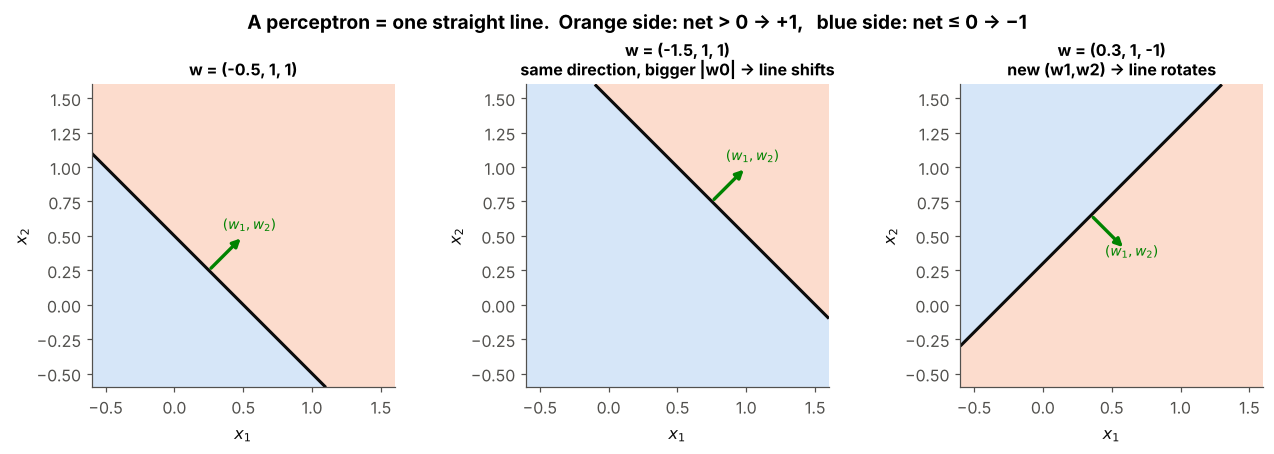

In [3]:
def draw_perceptron(ax, w, X=None, t=None, title="", lim=(-0.6, 1.6), show_vec=True):
    """Shade the YES/NO half-planes of weights w=[w0,w1,w2], draw the line and the data."""
    g = np.linspace(*lim, 400)
    xx, yy = np.meshgrid(g, g)
    net = w[0] + w[1] * xx + w[2] * yy                       # net input at every pixel
    ax.contourf(xx, yy, (net > 0).astype(int), levels=[-0.5, 0.5, 1.5], cmap=REGION_CMAP)
    if np.any(w[1:] != 0):
        ax.contour(xx, yy, net, levels=[0], colors=C["ink"], linewidths=2)   # the line net = 0
    if show_vec and np.any(w[1:] != 0):
        # put the arrow on the line, at the point closest to the centre of the plot
        c = np.array([np.mean(lim)] * 2)
        n = w[1:] / np.linalg.norm(w[1:])
        p = c - (w[0] + w[1:] @ c) / np.linalg.norm(w[1:]) * n
        ax.annotate("", xy=p + 0.35 * n, xytext=p,
                    arrowprops=dict(arrowstyle="-|>", color=C["green"], lw=2.2))
        ax.text(*(p + 0.42 * n), r"$(w_1,w_2)$", color=C["green"], fontsize=9, ha="center")
    if X is not None:
        ax.scatter(X[:, 0], X[:, 1], c=(t > 0).astype(int), cmap=POINT_CMAP, s=110,
                   edgecolor="white", linewidth=2, zorder=3)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title(title, fontsize=10.5)
    ax.grid(False)

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for ax, w_demo, txt in zip(axs,
        [np.array([-0.5, 1.0, 1.0]), np.array([-1.5, 1.0, 1.0]), np.array([0.3, 1.0, -1.0])],
        ["w = (-0.5, 1, 1)", "w = (-1.5, 1, 1)\nsame direction, bigger |w0| → line shifts",
         "w = (0.3, 1, -1)\nnew (w1,w2) → line rotates"]):
    draw_perceptron(ax, w_demo, title=txt)
fig.suptitle("A perceptron = one straight line.  Orange side: net > 0 → +1,   blue side: net ≤ 0 → −1",
             fontweight="bold")
plt.tight_layout(); plt.show()

---
## 5 · The perceptron learning rule 📏

We do not set the weights by hand – we **learn** them from examples. For every training example $(\vec x, t)$:

$$\boxed{\ w_i \leftarrow w_i + \Delta w_i,\qquad \Delta w_i = \eta\ (t - o)\ x_i\ }$$

Read every piece:
* $t - o$ = **"how wrong were we?"** Since $t,o\in\lbrace -1,+1\rbrace $, it is either $0$ (correct) or $\pm 2$ (wrong).
* $x_i$ = **"was input $i$ involved?"** If $x_i = 0$ the input could not have caused the mistake, so its weight is not touched.
* $\eta$ = **"how big a step?"** (e.g. 0.1).

| target $t$ | output $o$ | $t-o$ | what happens | intuition |
|---|---|---|---|---|
| +1 | +1 | 0 | nothing | correct → leave it alone |
| −1 | −1 | 0 | nothing | correct → leave it alone |
| +1 | −1 | **+2** | $w_i$ **increases** by $2\eta x_i$ | said NO, should be YES → push $net$ up |
| −1 | +1 | **−2** | $w_i$ **decreases** by $2\eta x_i$ | said YES, should be NO → push $net$ down |

**Why does it work?** After a "should be YES" update, the new net input is
$net_{new}=\sum_i (w_i + 2\eta x_i)x_i = net_{old} + 2\eta\sum_i x_i^2 > net_{old}$.
So the same example gets a **larger** net input next time – the line moves towards classifying it correctly.

Let's *see* one update.

before: w = [ 0.2 -0.6  0.5],  net = -0.25  → o = -1  (target +1: WRONG)
Δw = η (t - o) x = 0.3 × (1 - (-1)) × [1.  1.  0.3] = [0.6  0.6  0.18]
after : w = [0.8  0.   0.68],  net = +1.00  → o = +1  ✅


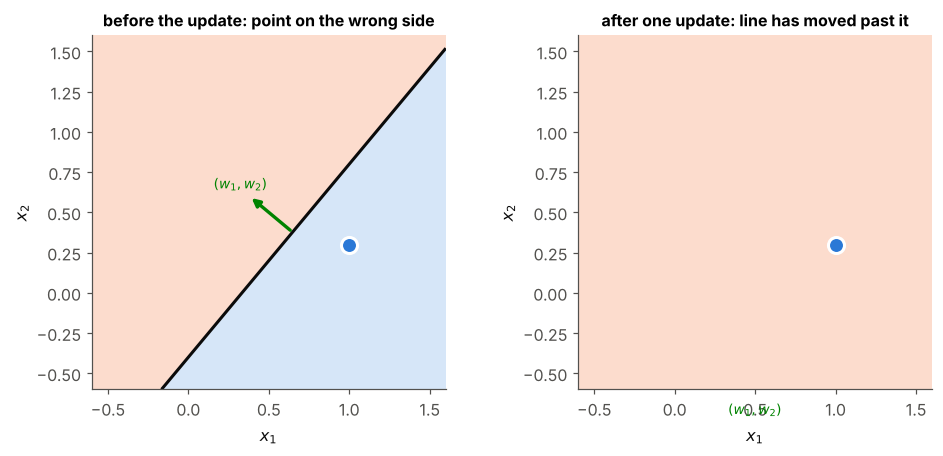

In [4]:
w_before = np.array([0.2, -0.6, 0.5])          # some current weights
x_wrong = np.array([1.0, 1.0, 0.3])            # example (x0=1, x1=1, x2=0.3), target +1
t_wrong, eta = +1, 0.3

net_before = w_before @ x_wrong
o_before = 1 if net_before > 0 else -1
w_after = w_before + eta * (t_wrong - o_before) * x_wrong      # the perceptron rule
net_after = w_after @ x_wrong

print(f"before: w = {w_before},  net = {net_before:+.2f}  → o = {o_before:+d}  (target +1: WRONG)")
print(f"Δw = η (t - o) x = {eta} × ({t_wrong} - ({o_before})) × {x_wrong} = {w_after - w_before}")
print(f"after : w = {w_after},  net = {net_after:+.2f}  → o = {1 if net_after > 0 else -1:+d}  ✅")

fig, axs = plt.subplots(1, 2, figsize=(9, 4.2))
pt = x_wrong[1:][None, :]
draw_perceptron(axs[0], w_before, pt, np.array([1]), "before the update: point on the wrong side")
draw_perceptron(axs[1], w_after, pt, np.array([1]), "after one update: line has moved past it")
plt.tight_layout(); plt.show()

---
## 6 · The implementation 💻

The class below is a direct translation of sections 3 and 5. Every line is commented. It also records a **history** (weights after each step, mistakes per epoch) so that we can plot how learning happens.

In [5]:
class ThresholdedPerceptron:
    """A single perceptron:  o = +1 if w·x > 0 else -1,  trained with  Δw = η (t - o) x."""

    def __init__(self, learning_rate=0.1, epochs=10):
        self.eta = learning_rate          # η : step size of every correction
        self.epochs = epochs              # how many passes over the dataset
        self.w = None                     # weights [w0, w1, ..., wn], created in fit()

    @staticmethod
    def add_bias(X):
        """Prepend the constant input x0 = 1 to every example (row)."""
        return np.c_[np.ones((X.shape[0], 1)), X]

    def fit(self, X, t, verbose=False):
        Xb = self.add_bias(X)                         # shape (N, n+1)
        self.w = np.zeros(Xb.shape[1])                # start with "no opinion"
        self.w_history = [self.w.copy()]              # weights after every single example
        self.mistakes = []                            # number of errors in each epoch
        for epoch in range(self.epochs):
            errors = 0
            for xi, ti in zip(Xb, t):                 # one example at a time (online learning)
                net = np.dot(self.w, xi)              # step 1: weighted sum
                o = 1 if net > 0 else -1              # step 2: hard threshold
                dw = self.eta * (ti - o) * xi         # perceptron rule
                if verbose:
                    print(f"ep{epoch+1} x={xi[1:]} t={ti:+d} net={net:+.2f} o={o:+d} "
                          f"Δw={dw + 0.0} → w={self.w + dw + 0.0}")
                self.w += dw
                errors += int(ti != o)
                self.w_history.append(self.w.copy())
            self.mistakes.append(errors)
            if errors == 0 and not verbose:           # every example correct → converged
                break
        return self

    def predict(self, X):
        """Vectorised prediction for many examples at once."""
        return np.where(self.add_bias(X) @ self.w > 0, 1, -1)

### 🔍 Code walk-through, step by step

| Line | What it does | Maths |
|---|---|---|
| `Xb = self.add_bias(X)` | glue a column of 1s in front of the data | $x_0 = 1$ |
| `self.w = np.zeros(...)` | all weights start at 0 → the neuron says −1 for everything | $\vec w=\vec 0$ |
| `for xi, ti in zip(Xb, t)` | visit examples one by one | – |
| `net = np.dot(self.w, xi)` | weighted sum | $net=\sum_i w_ix_i$ |
| `o = 1 if net > 0 else -1` | hard step | $o=\text{sgn}(net)$ |
| `dw = self.eta * (ti - o) * xi` | the learning rule, for **all** $i$ at once (NumPy vector maths) | $\Delta w_i=\eta(t-o)x_i$ |
| `self.w += dw` | apply the correction | $w_i\leftarrow w_i+\Delta w_i$ |
| `np.where(Xb @ w > 0, 1, -1)` | step function applied to every row in one go | – |

---
## 7 · Learning the AND gate, step by step ✅

| $x_1$ | $x_2$ | AND | target $t$ |
|---|---|---|---|
| 0 | 0 | 0 | −1 |
| 0 | 1 | 0 | −1 |
| 1 | 0 | 0 | −1 |
| 1 | 1 | 1 | **+1** |

We start from $\vec w=(0,0,0)$ with $\eta=0.1$ and print **every** update of the first two epochs, so you can check each number by hand.

In [6]:
X_gate = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)   # the 4 possible inputs
t_and = np.array([-1, -1, -1, 1])

ThresholdedPerceptron(learning_rate=0.1, epochs=2).fit(X_gate, t_and, verbose=True)

ep1 x=[0. 0.] t=-1 net=+0.00 o=-1 Δw=[0. 0. 0.] → w=[0. 0. 0.]
ep1 x=[0. 1.] t=-1 net=+0.00 o=-1 Δw=[0. 0. 0.] → w=[0. 0. 0.]
ep1 x=[1. 0.] t=-1 net=+0.00 o=-1 Δw=[0. 0. 0.] → w=[0. 0. 0.]
ep1 x=[1. 1.] t=+1 net=+0.00 o=-1 Δw=[0.2 0.2 0.2] → w=[0.2 0.2 0.2]
ep2 x=[0. 0.] t=-1 net=+0.20 o=+1 Δw=[-0.2  0.   0. ] → w=[0.  0.2 0.2]
ep2 x=[0. 1.] t=-1 net=+0.20 o=+1 Δw=[-0.2  0.  -0.2] → w=[-0.2  0.2  0. ]
ep2 x=[1. 0.] t=-1 net=+0.00 o=-1 Δw=[0. 0. 0.] → w=[-0.2  0.2  0. ]
ep2 x=[1. 1.] t=+1 net=+0.00 o=-1 Δw=[0.2 0.2 0.2] → w=[0.  0.4 0.2]


In [7]:
p_and = ThresholdedPerceptron(learning_rate=0.1, epochs=20).fit(X_gate, t_and)
print("mistakes per epoch :", p_and.mistakes)
print("final weights w    :", p_and.w, " (w0, w1, w2)")
print("predictions        :", p_and.predict(X_gate), "  targets:", t_and)

mistakes per epoch : [1, 3, 3, 2, 1, 0]
final weights w    : [-0.4  0.4  0.2]  (w0, w1, w2)
predictions        : [-1 -1 -1  1]   targets: [-1 -1 -1  1]


Read the final weights as a rule: $net=-0.4+0.4x_1+0.2x_2$. Only $(1,1)$ gives $net=0.2>0$; every other input gives $net\le 0$. That is AND. ✅

Now let us **watch the line move**. Each panel shows the line at the end of one epoch.

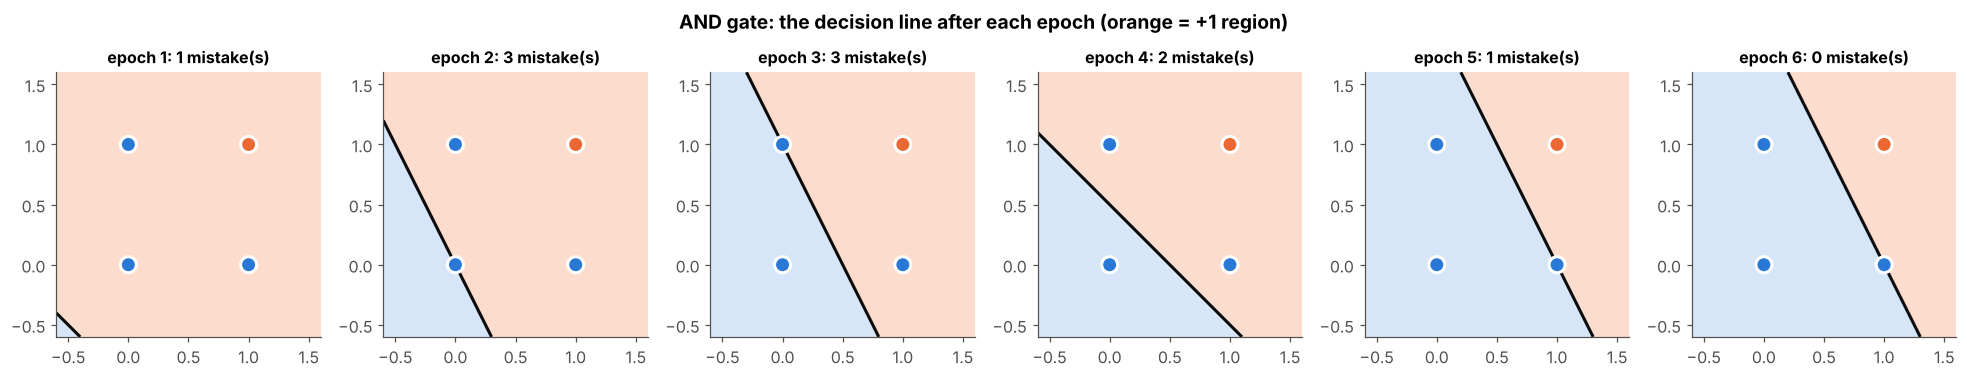

In [8]:
fig, axs = plt.subplots(1, len(p_and.mistakes), figsize=(3.0 * len(p_and.mistakes), 3.3))
for e, ax in enumerate(axs):
    w_e = p_and.w_history[(e + 1) * len(X_gate)]          # weights after epoch e+1
    draw_perceptron(ax, w_e, X_gate, t_and, f"epoch {e+1}: {p_and.mistakes[e]} mistake(s)",
                    show_vec=False)
    ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("AND gate: the decision line after each epoch (orange = +1 region)", fontweight="bold")
plt.tight_layout(); plt.show()

### OR and NAND are also lines – same code, different targets

AND   w = [-0.4  0.4  0.2]   mistakes per epoch = [1, 3, 3, 2, 1, 0]
OR    w = [0.  0.2 0.2]   mistakes per epoch = [1, 2, 1, 0]
NAND  w = [ 0.4 -0.4 -0.2]   mistakes per epoch = [2, 3, 3, 0]
XOR   w = [ 0.2 -0.2  0. ]   mistakes per epoch = [2, 3, 4, 4, 4, 4, 4, 4] ...


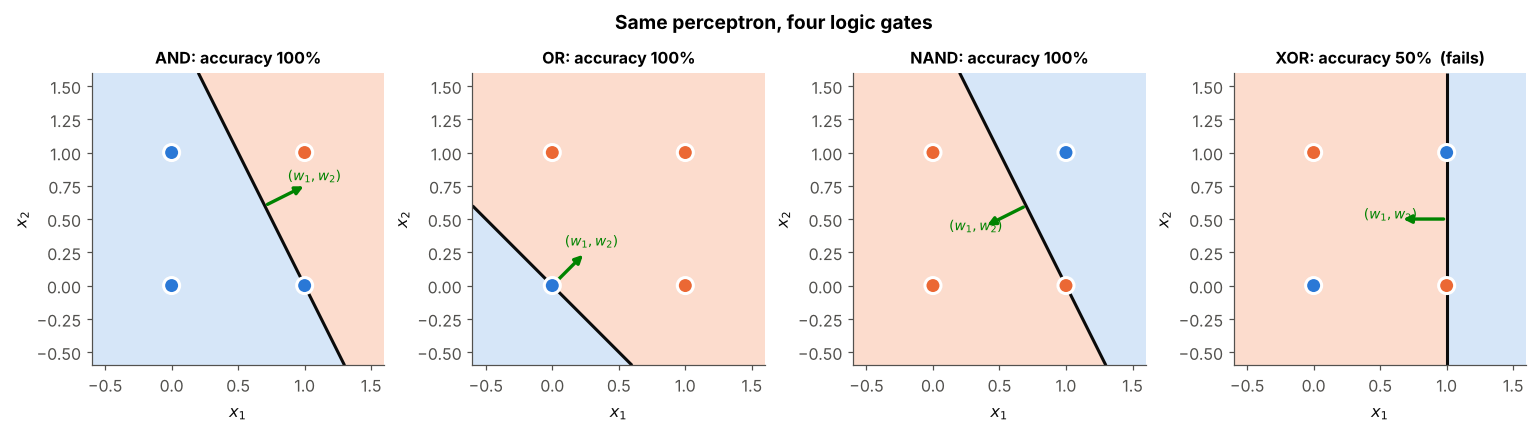

In [9]:
gates = {"AND":  np.array([-1, -1, -1, 1]),
         "OR":   np.array([-1, 1, 1, 1]),
         "NAND": np.array([1, 1, 1, -1]),
         "XOR":  np.array([-1, 1, 1, -1])}

fig, axs = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, (name, t_g) in zip(axs, gates.items()):
    p = ThresholdedPerceptron(learning_rate=0.1, epochs=30).fit(X_gate, t_g)
    acc = (p.predict(X_gate) == t_g).mean()
    draw_perceptron(ax, p.w, X_gate, t_g, f"{name}: accuracy {acc:.0%}" + ("  (fails)" if acc < 1 else ""))
    print(f"{name:<5} w = {p.w}   mistakes per epoch = {p.mistakes[:8]}{' ...' if len(p.mistakes) > 8 else ''}")
fig.suptitle("Same perceptron, four logic gates", fontweight="bold")
plt.tight_layout(); plt.show()

---
## 8 · Where it breaks: XOR ❌

XOR says YES when **exactly one** input is on. Look at the four points: the two orange (+1) points sit on one diagonal, the two blue (−1) points on the other. **No single straight line can separate them.**

### A 4-line proof
For XOR we would need:

| input | target | condition on the weights |
|---|---|---|
| (0,0) | −1 | $w_0 \le 0$ |
| (1,1) | −1 | $w_0+w_1+w_2 \le 0$ |
| (0,1) | +1 | $w_0+w_2 > 0$ |
| (1,0) | +1 | $w_0+w_1 > 0$ |

Add the two "+1" rows: $2w_0+w_1+w_2>0$. Add the two "−1" rows: $2w_0+w_1+w_2\le 0$. The same quantity cannot be both positive and non-positive → **contradiction**. No weights exist. ∎

So what does the learning rule do? It never stops correcting – the weights go **round in a cycle forever**:

In [10]:
p_xor = ThresholdedPerceptron(learning_rate=0.1, epochs=25).fit(X_gate, gates["XOR"])
W_hist = np.array(p_xor.w_history)
print("mistakes per epoch:", p_xor.mistakes[:10], "...")
print("weights at the end of epochs 1-5:")
for e in range(5):
    print(f"  epoch {e+1}: w = {W_hist[(e + 1) * 4] + 0.0}")

mistakes per epoch: [2, 3, 4, 4, 4, 4, 4, 4, 4, 4] ...
weights at the end of epochs 1-5:
  epoch 1: w = [ 0.  -0.2  0. ]
  epoch 2: w = [ 0.2 -0.2  0. ]
  epoch 3: w = [ 0.2 -0.2  0. ]
  epoch 4: w = [ 0.2 -0.2  0. ]
  epoch 5: w = [ 0.2 -0.2  0. ]


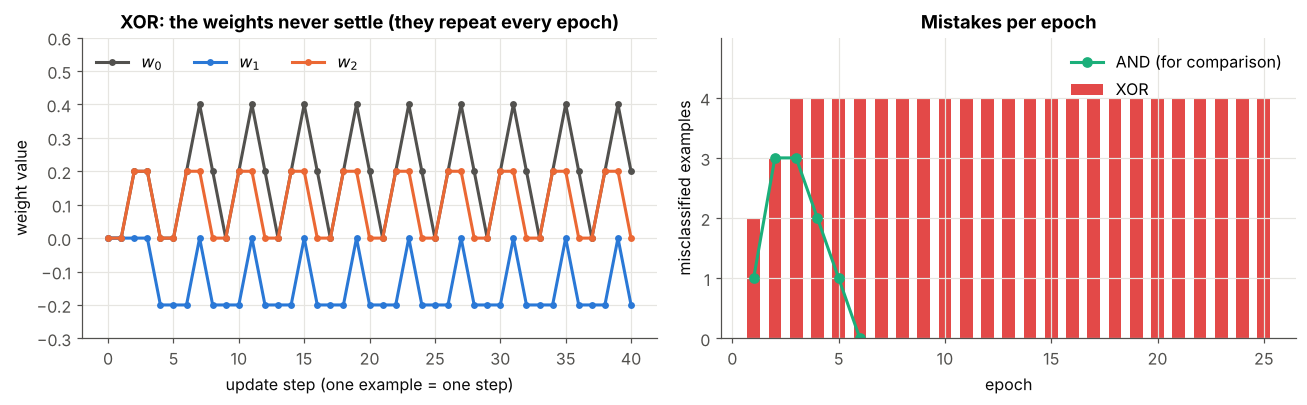

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
steps = np.arange(len(W_hist))
for i, (col, lab) in enumerate(zip([C["muted"], C["blue"], C["orange"]], ["$w_0$", "$w_1$", "$w_2$"])):
    axs[0].plot(steps[:41], W_hist[:41, i], "o-", ms=3.5, color=col, label=lab)
axs[0].set_title("XOR: the weights never settle (they repeat every epoch)")
axs[0].set_xlabel("update step (one example = one step)"); axs[0].set_ylabel("weight value")
axs[0].set_ylim(-0.3, 0.6); axs[0].legend(ncol=3, loc="upper left")

ep = np.arange(1, 26)
axs[1].bar(ep, p_xor.mistakes, color=C["red"], width=0.6, label="XOR")
axs[1].plot(np.arange(1, len(p_and.mistakes) + 1), p_and.mistakes, "o-", color=C["aqua"], label="AND (for comparison)")
axs[1].set_title("Mistakes per epoch"); axs[1].set_xlabel("epoch"); axs[1].set_ylabel("misclassified examples")
axs[1].set_ylim(0, 5); axs[1].set_yticks(range(5)); axs[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

> ⚠️ **Two problems we must fix next**
> 1. **One line is not enough.** XOR (and almost every real problem) needs a curved boundary → we will need *layers* of neurons.
> 2. **The step function has slope 0 everywhere** (and is undefined at 0). So inside a network we would have no way to tell how a hidden neuron's weight should change – the notes say: *"Do not know how to update intermediate neuron."*
>
> The first fix (notebook 02) is to **remove the threshold** so we can measure *how* wrong we are and use calculus.

---
## 9 · Bonus: the convergence theorem in action 🏁

**Perceptron convergence theorem (from the notes):** *"If the data is linearly separable, it will find the hyperplane"* – in a finite number of updates, for any $\eta>0$.

Below: 100 random points that a line *can* separate. We train and watch the mistakes fall to zero.

89 points, converged after 22 epochs, final accuracy = 100%


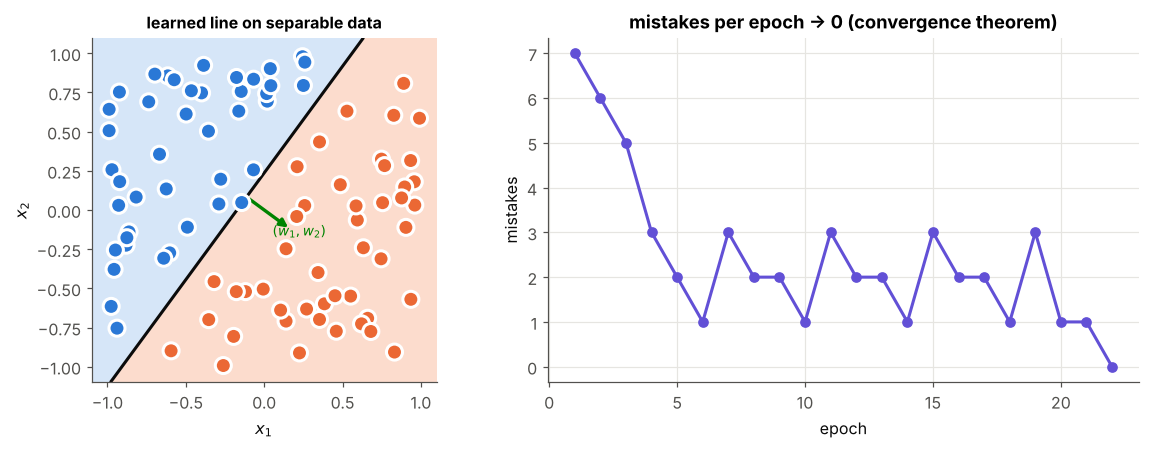

In [12]:
rng = np.random.default_rng(7)
X_sep = rng.uniform(-1, 1, size=(100, 2))
true_w = np.array([0.1, 1.0, -0.8])                       # hidden "true" line used to label the data
t_sep = np.where(true_w[0] + X_sep @ true_w[1:] > 0, 1, -1)
keep = np.abs(true_w[0] + X_sep @ true_w[1:]) > 0.08       # leave a small margin around the line
X_sep, t_sep = X_sep[keep], t_sep[keep]

p_sep = ThresholdedPerceptron(learning_rate=0.1, epochs=100).fit(X_sep, t_sep)
print(f"{len(X_sep)} points, converged after {len(p_sep.mistakes)} epochs, "
      f"final accuracy = {(p_sep.predict(X_sep) == t_sep).mean():.0%}")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw=dict(width_ratios=[1, 1.3]))
draw_perceptron(axs[0], p_sep.w, X_sep, t_sep, "learned line on separable data", lim=(-1.1, 1.1))
axs[1].plot(np.arange(1, len(p_sep.mistakes) + 1), p_sep.mistakes, "o-", color=C["violet"])
axs[1].set_title("mistakes per epoch → 0 (convergence theorem)")
axs[1].set_xlabel("epoch"); axs[1].set_ylabel("mistakes")
plt.tight_layout(); plt.show()

---
## 10 · Summary 📌

| Concept | Formula / fact |
|---|---|
| Net input | $net=\sum_{i=0}^{n}w_ix_i=\vec w\cdot\vec x$, with $x_0=1$ |
| Output | $o=+1$ if $net>0$, else $-1$ |
| Learning rule | $\Delta w_i=\eta\ (t-o)\ x_i$ |
| Decision boundary | the hyperplane $\vec w\cdot\vec x=0$ (a straight line in 2-D) |
| Works for | **linearly separable** data (AND, OR, NAND) – guaranteed to converge |
| Fails for | XOR and any data that no single line can split |
| Can't be used inside a network because | the step has zero slope → no gradient |

### ✍️ Try it yourself
1. Re-run the AND experiment with $\eta = 1$. Do the mistakes per epoch change? Do the final weights? *(Hint: with $\vec w_{start}=\vec 0$, scaling $\eta$ only scales $\vec w$.)*
2. Change the order of the 4 training examples. Does it still converge? To the same line?
3. Build a 3-input majority gate (output +1 if at least two inputs are 1) and train it.
4. Can a perceptron learn the regression example from the notes ($x=1,2,3 \to y=2,6,10$)? Why not? *(It only outputs ±1!)*

**Next →** `02 - Unthresholded Perceptron and Delta Rule`: remove the step, define an error, and roll downhill with gradient descent.